In [2]:
# 1. Import libraries (Only K-Means, DBSCAN, and PCA from sklearn models)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


df = pd.read_csv("marketing_campaign.csv", sep=None, engine="python")

print("Dataset shape:", df.shape)
display(df.head())

print("\nMissing values (top columns):")
display(df.isna().sum().sort_values(ascending=False).head(10))

Dataset shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0



Missing values (top columns):


,0
Income,24
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [3]:
# 2. Prepare the data using pure Pandas
data = df.copy()

# Convert enrollment date and calculate customer tenure in days
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], dayfirst=True, errors="coerce")
latest_date = data["Dt_Customer"].max()
data["Customer_Tenure_Days"] = (latest_date - data["Dt_Customer"]).dt.days

# Remove identifier, original date, constant columns, and campaign response
data = data.drop(
    columns=["ID", "Dt_Customer", "Z_CostContact", "Z_Revenue", "Response"],
    errors="ignore"
)

# Separate numerical and categorical columns
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
categorical_cols = data.select_dtypes(include="object").columns.tolist()

# 1. Fill missing numerical values with the median
for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

# 2. Fill missing categorical values with the most frequent value (mode)
for col in categorical_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

# 3. Standardize numerical features (Z-score scaling: (x - mean) / std)
for col in numeric_cols:
    data[col] = (data[col] - data[col].mean()) / data[col].std(ddof=0)

# 4. One-hot encode categorical features using pandas get_dummies
data_encoded = pd.get_dummies(data, columns=categorical_cols, dtype=float)

# Convert to numpy array for clustering
X = data_encoded.values

print("Rows used:", X.shape[0])
print("Features after encoding:", X.shape[1])
print("Numerical features:", len(numeric_cols))
print("Categorical features:", categorical_cols)

Rows used: 2240
Features after encoding: 36
Numerical features: 23
Categorical features: ['Education', 'Marital_Status']


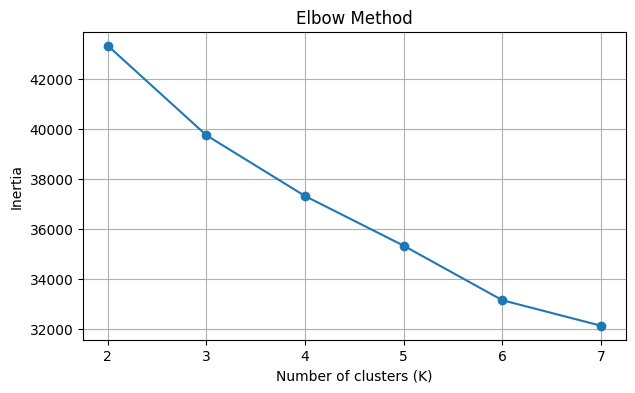

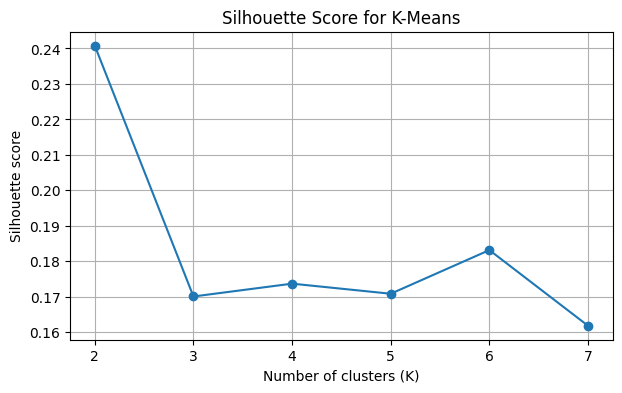

Silhouette scores: {2: np.float64(0.241), 3: np.float64(0.17), 4: np.float64(0.174), 5: np.float64(0.171), 6: np.float64(0.183), 7: np.float64(0.162)}


In [4]:
# 3. K-Means clustering - Finding optimal K
inertias = []
silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

print("Silhouette scores:", {k: round(s, 3) for k, s in zip(k_values, silhouette_scores)})

In [5]:
# Fit K-Means with K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

results = df.copy()
results["KMeans_Cluster"] = kmeans_labels

print("K-Means cluster sizes:")
display(results["KMeans_Cluster"].value_counts().sort_index().rename("Customers").to_frame())

# Summarize numerical behavior by cluster
summary_cols = [c for c in [
    "Income", "MntWines", "MntMeatProducts", "MntFishProducts",
    "MntSweetProducts", "MntGoldProds", "NumWebPurchases",
    "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth",
    "Recency"
] if c in results.columns]
display(results.groupby("KMeans_Cluster")[summary_cols].mean().round(1))

K-Means cluster sizes:


,Customers
KMeans_Cluster,
0,30
1,634
2,1038
3,538


,Income,MntWines,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Recency
KMeans_Cluster,,,,,,,,,,,
0,71054.8,898.7,250.3,38.7,30.6,66.4,4.9,5.2,8.2,5.2,48.7
1,58088.1,456.0,140.2,32.1,24.9,60.2,6.4,3.1,7.8,5.7,48.4
2,34908.5,42.0,23.5,7.0,5.1,15.4,2.1,0.6,3.2,6.4,49.4
3,77694.1,597.1,470.6,102.6,71.9,79.0,5.1,6.1,8.3,2.7,49.5


In [6]:
# 4. DBSCAN clustering
dbscan = DBSCAN(eps=4.0, min_samples=10)
dbscan_labels = dbscan.fit_predict(X)
results["DBSCAN_Cluster"] = dbscan_labels

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))

print("DBSCAN clusters found (excluding noise):", n_clusters)
print("Customers labelled as noise:", n_noise)
print("Noise percentage:", round(100 * n_noise / len(dbscan_labels), 2), "%")
print("\nDBSCAN label counts (-1 means noise):")
display(pd.Series(dbscan_labels, name="DBSCAN_Cluster").value_counts().sort_index().to_frame())

DBSCAN clusters found (excluding noise): 5
Customers labelled as noise: 255
Noise percentage: 11.38 %

DBSCAN label counts (-1 means noise):


,count
DBSCAN_Cluster,
-1,255
0,1900
1,41
2,10
3,11
4,23


Explained variance ratio: [0.265 0.086]
Total variance shown in 2D: 35.08 %


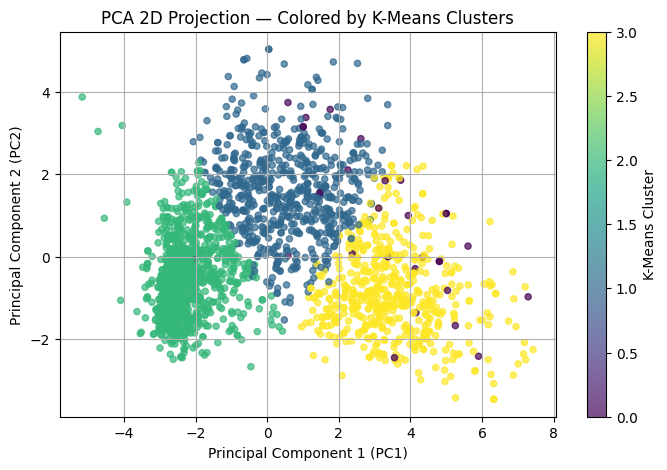

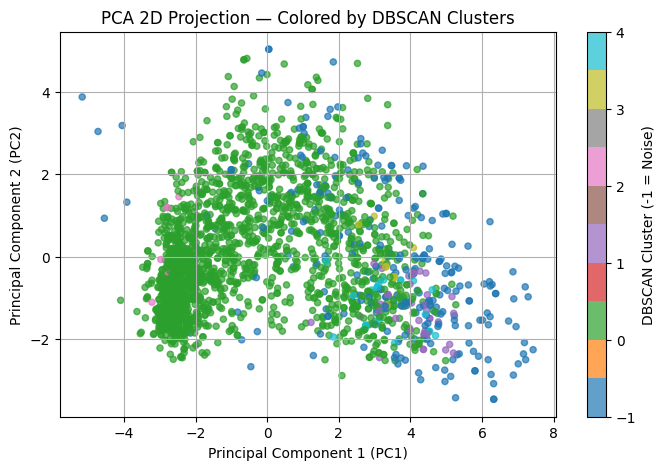

In [7]:
# 5. Visualize high-dimensional data with PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 3))
print("Total variance shown in 2D:", round(100 * np.sum(pca.explained_variance_ratio_), 2), "%")

# Plot 1: PCA colored by K-Means Clusters
plt.figure(figsize=(8, 5))
scatter1 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="viridis", s=20, alpha=0.7)
plt.colorbar(scatter1, label="K-Means Cluster")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA 2D Projection — Colored by K-Means Clusters")
plt.grid(True)
plt.show()

# Plot 2: PCA colored by DBSCAN Clusters
plt.figure(figsize=(8, 5))
scatter2 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap="tab10", s=20, alpha=0.7)
plt.colorbar(scatter2, label="DBSCAN Cluster (-1 = Noise)")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA 2D Projection — Colored by DBSCAN Clusters")
plt.grid(True)
plt.show()